# 03 · Explore the data

Before building any model, I look at how success relates to draft position and to the other
facts known on draft night. I answer 5 questions:

1. What can a team expect from each pick?
2. How often does each pick range produce a hit?
3. How uncertain is each pick range?
4. Has drafting changed over time?
5. Do college background and age matter beyond the pick number?

This notebook reads the file from notebook 02 and does not save a new data file.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

## Load the data

I load `draft_players_targets.csv` from notebook 02, because it has the `hit` column.
1,742 picks, one row each.

In [2]:
players = pd.read_csv("../data/processed/draft_players_targets.csv")
print(len(players))
players.head()

1742


,player_id,player,draft_year,overall_pick,round,draft_team,college,background,age_at_draft,height_in,weight_lb,pos_main,played_nba,ws_first4,games_first4,ws_career,games_career,seasons_played,hit
0,ellispe01,Pervis Ellison,1989,1,1.0,SAC,Louisville,college,22.2,81.0,210.0,F,True,15.2,225,21.9,474,11,True
1,ferryda01,Danny Ferry,1989,2,1.0,LAC,Duke,college,22.7,82.0,230.0,F,True,5.9,225,34.7,917,13,False
2,elliose01,Sean Elliott,1989,3,1.0,SAS,Arizona,college,21.4,80.0,205.0,F,True,27.9,315,55.6,742,12,True
3,ricegl01,Glen Rice,1989,4,1.0,MIA,Michigan,college,22.1,80.0,215.0,F,True,20.0,315,88.7,1000,15,True
4,reidjr01,J.R. Reid,1989,5,1.0,CHH,UNC,college,21.2,81.0,247.0,F,True,8.4,296,22.5,672,11,False


## Q1 · What can a team expect from each pick?

For each pick number (1–60), I take the **median** `ws_first4` of every player chosen there
across 30 drafts. This is the **expected value** of the pick: what a typical player at that spot produced.

The raw numbers are **noisy**. Each pick has only about 30 players, so a few busts can drag one pick down
(pick 2 is lower than pick 3, and pick 8 is lower than picks 7 and 9). To see the real trend, I add a
**smoothed line** (a rolling median over 5 neighbouring picks).

**Findings**
- Expected value drops steeply from pick 1 to about pick 15 (smoothed: ~19 → ~6).
- It flattens around picks 15–25 (~5): moving up a few spots here changes little.
- It falls close to zero around picks 31–33, where the **second round** starts. First-round picks get
  guaranteed contracts and playing time; second-rounders often don't.
- From about pick 48, the median pick produces 0 win shares.

**Cautions:** smoothing blurs real jumps at the edges. Pick 1's real median is 24.45, but the smoothed line shows ~19.

In [4]:
by_pick = players.groupby("overall_pick")["ws_first4"].median()
print(by_pick.head(10))

overall_pick
1     24.45
2     13.70
3     19.00
4     12.75
5     15.95
6     10.70
7     11.60
8      6.30
9     11.05
10    10.05
Name: ws_first4, dtype: float64


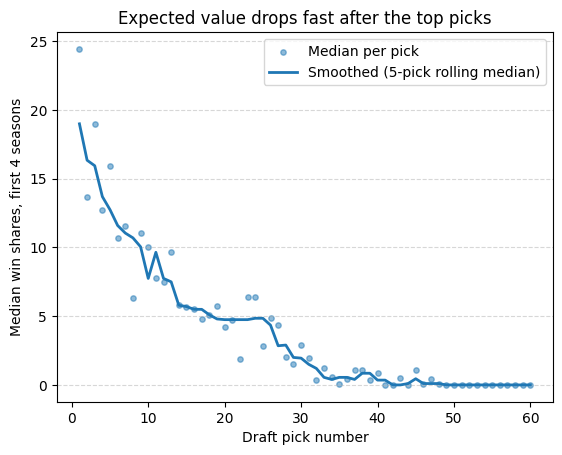

In [66]:
smooth = by_pick.rolling(5, center=True, min_periods=1).median()

plt.scatter(by_pick.index, by_pick, s=15, alpha=0.5, label="Median per pick")
plt.plot(smooth.index, smooth, linewidth=2, label="Smoothed (5-pick rolling median)")
plt.xlabel("Draft pick number")
plt.ylabel("Median win shares, first 4 seasons")
plt.title("Expected value drops fast after the top picks")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

## Q2 · How often does each pick range produce a hit?

I group picks into 4 ranges that mean something in the NBA, using `pd.cut`:

| Range | What it is |
|---|---|
| 1–5 | the very top picks |
| 6–14 | the rest of the lottery |
| 15–30 | the rest of the first round |
| 31–60 | the second round |

The **hit rate** is the share of picks in a range with 10+ win shares in their first 4 seasons
(the mean of the True/False `hit` column).

**Findings:** 72% (1–5), 44% (6–14), 26% (15–30), 8% (31–60).
A higher pick clearly improves the odds, but about 1 in 4 top-5 picks still misses,
and about 1 in 12 second rounders still becomes a useful player.

pick_range
1-5      0.720000
6-14     0.437037
15-30    0.264151
31-60    0.079290
Name: hit, dtype: float64


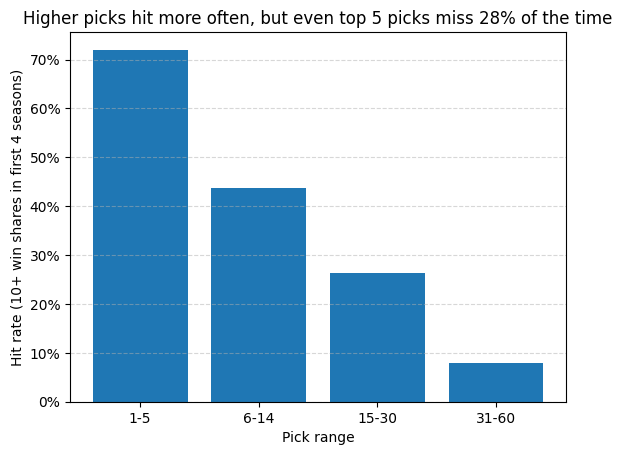

In [94]:
bins = [0, 5, 14, 30, 60]
labels = ["1-5", "6-14", "15-30", "31-60"]
players["pick_range"] = pd.cut(players["overall_pick"], bins=bins, labels=labels)

hit_rate = players.groupby("pick_range", observed=True)["hit"].mean()
print(hit_rate)

plt.bar(hit_rate.index, hit_rate)
plt.xlabel("Pick range")
plt.ylabel("Hit rate (10+ win shares in first 4 seasons)")
plt.title("Higher picks hit more often, but even top 5 picks miss 28% of the time")
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

## Q3 · How uncertain is each pick range?

The hit rate gives one number per range. A **box plot** shows the whole spread:
- the line in the box is the median
- the box holds the middle 50% of players
- the whiskers show the normal range
- the circles are **outliers**: players far better than the rest of their range

I kept the outliers. They are real players, not data errors, and they are the stars teams want to find.

**Findings**
- Medians fall from about 16 → 9 → 4 → 0.
- The boxes overlap: a good 15–30 pick (~10) matches a weak top-5 pick (~10).
- The best second-rounders (~27) beat the **typical** top-5 pick (~16).
- Every range has both busts and stars, so draft position matters, but the outcome is uncertain.

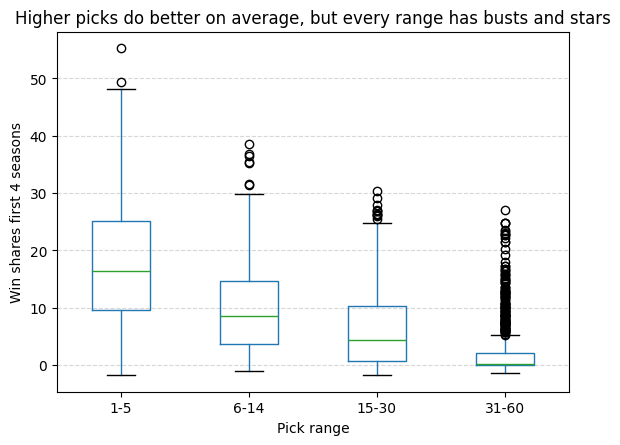

In [63]:
players.boxplot(column="ws_first4", by="pick_range", grid=False)
plt.xlabel("Pick range")
plt.ylabel("Win shares first 4 seasons")
plt.suptitle("")
plt.title("Higher picks do better on average, but every range has busts and stars")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

## Q4 · Has drafting changed over time?

I split drafts into 3 eras (1989–98, 1999–08, 2009–18) and compare hit rates by era and pick range,
using a pivot table.

| Era | 1–5 | 6–14 | 15–30 | 31–60 |
|---|---|---|---|---|
| 1989–98 | 82% | 46% | 23% | 5% |
| 1999–08 | 78% | 40% | 32% | 9% |
| 2009–18 | 56% | 46% | 24% | 9% |

**Findings**
- The top-5 hit rate dropped from 82% to 56%. The other ranges stayed about the same.
- **Caution:** each era has only 50 top-5 picks (10 drafts × 5), so 82% vs 56% is 41 vs 28 players.
  Part of this drop could be chance. It is a pattern worth noting, not a proven trend.
- Possible reasons (not tested): since 2006 players must be 19 to enter the draft, so top picks are
  often only one year out of college, and more top picks are international.

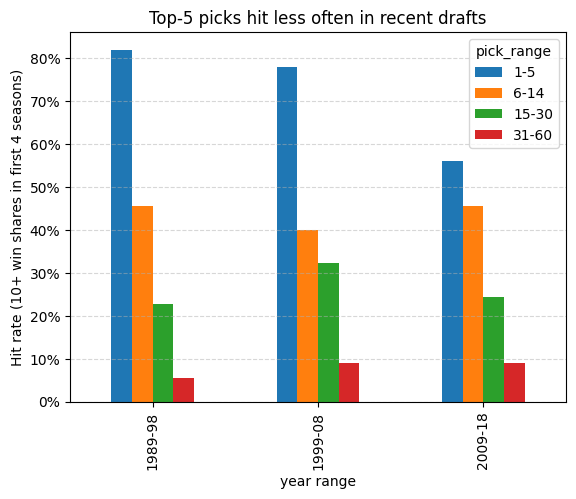

In [ ]:
bin = [1988, 1998, 2008, 2018]
labels = ["1989-98", "1999-08", "2009-18"]

players["year_range"] = pd.cut(players["draft_year"], bins=bin, labels=labels)
table = players.pivot_table(index="year_range", columns="pick_range", values="hit", aggfunc="mean", observed=True)

table.plot(kind="bar")
plt.xlabel("year range")
plt.ylabel("Hit rate (10+ win shares in first 4 seasons)")
plt.title("Top-5 picks hit less often in recent drafts")
plt.gca().yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

## Q5a · Does college background matter beyond the pick number?

If players with no college were simply picked later, they would hit less often because of their pick,
not their background. So I compare them **within the same pick range**.

| | 1–5 | 6–14 | 15–30 | 31–60 |
|---|---|---|---|---|
| college | 75% | 45% | 28% | 9% |
| no_college | 55% | 36% | 19% | 5% |

**Findings**
- No-college players hit less often at **every** pick range, so `background` may add information
  beyond the pick number. It is a candidate feature for the model in phase 4.
- **Cautions:** the no-college groups are small (about 22 players in the 1–5 range). "No college" is mostly
  international players, and some stay overseas for a few years after being drafted, which counts as
  0 in my 4-season window. So part of the gap may be delay, not talent.

In [106]:
bg = players.groupby("background")["hit"].mean()

hit_by_background = players.pivot_table(index="background", columns="pick_range", values="hit", aggfunc="mean", observed=True)

(hit_by_background *100).round(2)


pick_range,1-5,6-14,15-30,31-60
background,,,,
college,75.00,44.63,28.02,8.75
no_college,54.55,35.71,19.32,4.68


## Q5b · Does age at draft matter beyond the pick number?

I use **only the 1,502 players who played**, because age is missing for the 240 who never played
(see notebook 01).

Overall, younger draftees do better (correlation of −0.21 between age and `ws_first4`).
But when I compare the median `ws_first4` **within the same pick range**, age makes little consistent difference:

| Age | 1–5 | 6–14 | 15–30 | 31–60 |
|---|---|---|---|---|
| ≤20 | 13.7 | 8.0 | 4.6 | 1.8 |
| 20–21 | 17.7 | 8.0 | 4.4 | 0.5 |
| 21–22 | 16.8 | 10.4 | 4.5 | 0.6 |
| 22–23 | 16.6 | 8.9 | 4.1 | 0.8 |
| 23+ | 15.9 | 5.5 | 5.3 | 0.5 |

Why does age look important overall? Because older players tend to be picked later
(median pick: 14 for ≤20, 34 for 23+), and later picks do worse.

**Finding:** age is **confounded** with pick number. Teams already price age into the pick, so age adds
little once the pick number is known.

In [114]:
played = players[players["played_nba"]].copy()
corr_age = played["age_at_draft"].corr(played["ws_first4"])

print(f"Correlation between age and ws_first4: {corr_age.round(2)}")

Correlation between age and ws_first4: -0.21


In [119]:
bins = [0, 20, 21, 22, 23, 30] 
labels = ["≤20", "20-21", "21-22", "22-23", "23+"]
played["age_group"] = pd.cut(played["age_at_draft"], bins=bins, labels=labels)
age_table = played.pivot_table(index="age_group", columns="pick_range", values="ws_first4", aggfunc="median", observed=True)
pick_by_age = played.groupby("age_group", observed=True)["overall_pick"].median()

print("Age Table:")
print(age_table)

print("\nPick by Age:")
print(pick_by_age)

Age Table:
pick_range    1-5   6-14  15-30  31-60
age_group                             
≤20         13.65   8.00   4.60    1.8
20-21       17.70   8.00   4.40    0.5
21-22       16.80  10.35   4.50    0.6
22-23       16.60   8.90   4.05    0.8
23+         15.90   5.50   5.30    0.5

Pick by Age:
age_group
≤20      14.0
20-21    20.0
21-22    25.5
22-23    31.0
23+      34.0
Name: overall_pick, dtype: float64


## Summary

- Draft position matters: expected value and hit rate fall steeply from the top picks to the second round.
- But it isn't destiny: every pick range has busts and stars, and the ranges overlap.
- Top-5 picks hit less often in recent drafts (a pattern, not proven).
- College background may add information beyond the pick; age mostly does not (confounding).

**For phase 4:** the model will use pick number, plus draft-night facts known for every pick such as
`background`. Age stays out of the main model because it is missing for players who never played.